[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bastifwp/SOCHIAS/blob/main/regressionDL_SOCHIAS.ipynb)

# Prediction of Stellar Parameters in Massive Stars 
---
**Objectives:**  
* Learn how to use Deep Learning models to predict stellar parameters from the spectra of massive stars
* Learn how to estimate the uncertainty of a Deep learning model


**Data:**  
* A subset of the ISOSCELES database will be used, focusing specifically on the H-alpha spectral line and fixing the microturbulent velocity at 10 km/s.

* Observed spectra to validate performance.

* Parameters: **effective temperature, log g, and mass-loss rate** 

---
### Notebook Summary
We will address this problem as a multi-output regression task.

In this activity:  
1. Exploratory Data Analysis (EDA)
2. Data preprocessing 
3. Model training and evaluation
4. Model modifications to estimate prediction uncertainties


## Python Libraries
*tools already implemented that we can use*
***

In [1]:
import os
import sys

#Data managment
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

#Model evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


#Deep learning
import tensorflow as tf
import keras
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout, SpatialDropout1D



### Custom functions
---

In [2]:
def plot_spectrum(wavelengths, flux, title="Spectrum", figsize=(10,5)):
    """
    Plot a stellar spectrum using an astrophysics-style dark theme.
    """

    #Create a figure where to plot
    plt.style.use("dark_background")
    plt.figure(figsize=figsize)

    #Draw the plot 
    plt.plot(wavelengths, flux, color="cyan", linewidth=1.8)

    #Visual configs
    plt.title(title, fontsize=14, color="white")
    plt.xlabel("Wavelength [Å]", fontsize=12, color="white")
    plt.ylabel("Flux", fontsize=12, color="white")
    plt.grid(color="gray", alpha=0.3, linestyle="--")

    #Show the figure
    plt.tight_layout()
    plt.show()



def plot_histogram_science_style(data, title="Histogram", xlabel="Value", color="#3b82f6",):
    """
    Plot a histogram with KDE using a clean, scientific style.

    Parameters
    ----------
    data : array-like
        Array of values to plot.
    title : str
        Title of the plot.
    xlabel : str
        Label for the x-axis.
    color : str
        Color of the histogram bars and KDE line.
    """

    #Create figure
    sns.set_theme(style="ticks")        
    plt.figure(figsize=(6,4))

    #draw histogram
    sns.histplot(
        data,
        kde=True,
        color=color,
        edgecolor="black",
        linewidth=0.7
    )

    #Visual configs
    sns.despine()                      
    plt.title(title, fontsize=15)
    plt.xlabel(xlabel, fontsize=13)
    plt.ylabel("Frequency", fontsize=13)

    #Show the figure
    plt.tight_layout()
    plt.show()



def plot_true_pred_hist(true_values, pred_values, title="Comparison"):
    """
    Plot overlapping histograms (true vs predicted) with KDE curves.

    Parameters
    ----------
    true_values : array-like
        Ground truth values.
    pred_values : array-like
        Predicted values.
    title : str
        Graph title.
    """

    #Create a figure
    sns.set_theme(style="ticks", context="talk")
    plt.figure(figsize=(8,5))

    #Draw true values histogram in figure
    sns.histplot(true_values, kde=True, stat="density",
                 color="steelblue", label="True", alpha=0.7,
                 edgecolor="black", linewidth=0.8, bins=50)

    #Draw pred values histogram in figure
    sns.histplot(pred_values, kde=True, stat="density",
                 color="salmon", label="Pred", alpha=0.7,
                 edgecolor="black", linewidth=0.8, bins=50)

    #Visual configs
    plt.title(title, fontsize=16)
    plt.xlabel("Value", fontsize=14)
    plt.ylabel("Density", fontsize=14)
    plt.legend()
    sns.despine()

    #Show figure
    plt.tight_layout()
    plt.show()



def plot_results(y_test, y_pred, model_name, targets=["T_eff", "Log g", "LOGMDOT"]):
    """
    Show error metrics: MSE, MAE, R^2
    Plot predictions v/s real values
    """
    n_targets = len(targets)

    #Metrics report
    for i, target in enumerate(targets):
        print(f"{target} – {model_name}")
        print(f"  MSE: {mean_squared_error(y_test[:, i], y_pred[:, i]):.2f}")
        print(f"  MAE: {mean_absolute_error(y_test[:, i], y_pred[:, i]):.2f}")
        print(f"  R²:  {r2_score(y_test[:, i], y_pred[:, i]):.3f}\n")

    #Scatter plot: model predictions v/s real
    plt.figure(figsize=(7 * n_targets, 5))

    for i, target in enumerate(targets):
        true = y_test[:, i]
        pred = y_pred[:, i]

        plt.subplot(1, n_targets, i + 1)

        #Perfect prediction line
        lims = [true.min(), true.max()]
        plt.plot(lims, lims, color="crimson", linestyle="--", linewidth=2, label="Perfect prediction")

        #Predictions
        plt.scatter(true, pred, color="royalblue", alpha=0.4, s=15, label="Predictions")

        plt.xlabel(f"True {target}")
        plt.ylabel(f"Predicted {target}")
        plt.title(f"{target} – {model_name}")
        plt.legend(loc="upper left")
        plt.grid(True, linestyle="--", alpha=0.4)
        sns.despine()

    plt.tight_layout()
    plt.show()


## 1. Exploratory Data Analysis (EDA)
---

#### Data download

In [3]:
#Dataset provided by PhD (c) Daniela Turis, IFA-UV.

#Check if you are running in Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    #Download using gdown
    import gdown
    !gdown https://drive.google.com/uc?id=14NHeV1fvE2HXMaghHAszf_92iTBVNJHL
    !gdown  https://drive.google.com/uc?id=1g56JSd46v1HjJkhpIw7Qkal--VDd7cpS
    !gdown  https://drive.google.com/uc?id=1YA9HYeOKHMYvt9M4LAaLkO8mpJjOXktV
    !gdown  https://drive.google.com/uc?id=1sClZIPaj9mJaPDp2r8UNdN94zgA55NDR

    data = np.load("subset_vmic10.npy")
    params = np.load("y_subset_vmic10.npy") 
    data_observed = np.load("X_observed.npy")
    data_observed_p = np.load("X_observed_processed.npy")

else:
    #Search files in local distk
    dir_path = "Data/DL/"
    if os.path.exists(dir_path):
        data = np.load(dir_path + "subset_vmic10.npy")
        params = np.load(dir_path + "y_subset_vmic10.npy")
        data_observed = np.load(dir_path + "X_observed.npy")
        data_observed_p = np.load(dir_path + "X_observed_processed.npy")
        print("Files loaded")

    else:
        print("File not found. Please download it or check the file path.")

Files loaded


#### Inspect the data


In [4]:
print("Data shape:", data.shape)
print("params shape:", params.shape)


Data shape: (10000, 200)
params shape: (10000, 9)


The `params` variable contains the parameters for each spectrum

| Parameter | Description |
| :--- | :--- |
| `TEFF` | Effective temperature |
| `LOGG` | Logarithm of the surface gravity |
| `LOGSTAR` | Logarithm of the stellar luminosity |
| `ALPHA`, `K`, `DELTA` | Line-strength parameters |
| `VINF` | Terminal velocity |
| `LOGMDOT` | Logarithm of the mass-loss rate |
| `SI` | Silicon abundance |

We will select only `TEFF`, `LOGG`, and `LOGMDOT`

In [5]:
y_new = params[:, [0, 1, 7]] #Select all rows and the columns 0,1 and 7

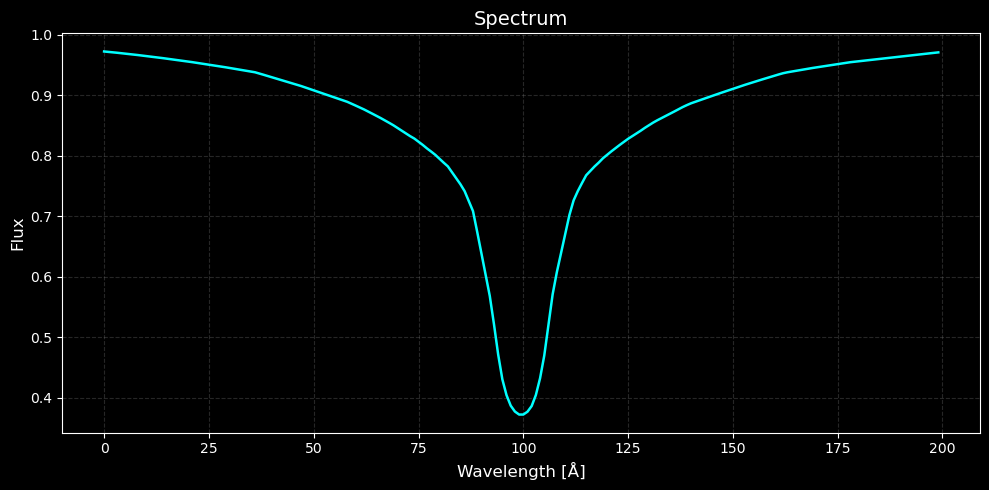

In [6]:
plot_spectrum(range(200), data[0])

#### Parameters distributions



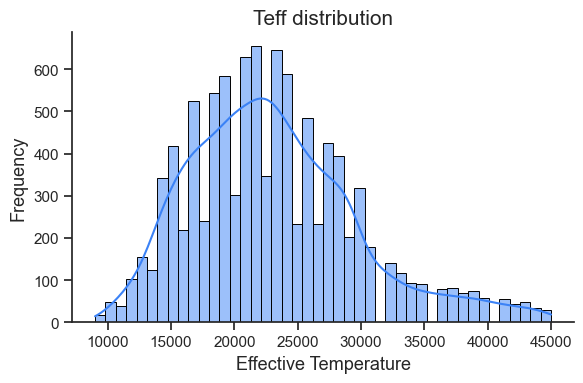

In [7]:
plot_histogram_science_style(y_new[:, 0], title= "Teff distribution", xlabel="Effective Temperature")

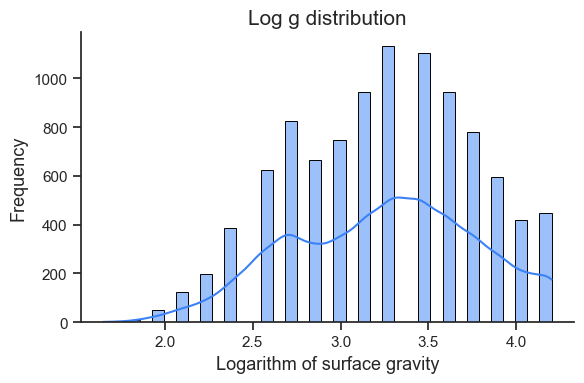

In [8]:
plot_histogram_science_style(
    y_new[:, 1],
    title="Log g distribution",
    xlabel="Logarithm of surface gravity"
)

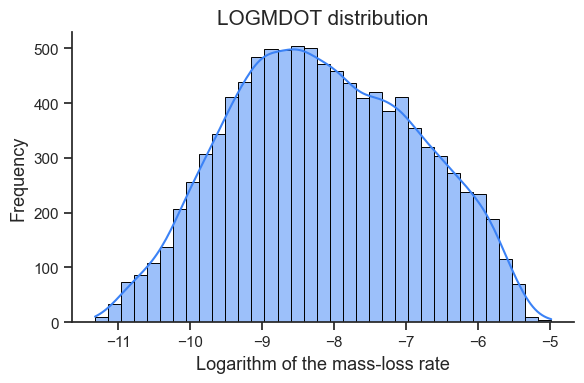

In [9]:
plot_histogram_science_style(
    y_new[:, 2],
    title="LOGMDOT distribution",
    xlabel="Logarithm of the mass-loss rate"
)

## 2. Data preprocessing
---
In machine lerning, it is common to create a matrix $X$ for the input data and a matrix $y$ for the target outputs. We will train a  1D `Convolutional Neural Network` (CNN) to predict the stellar parameters

* $X$ will contain the $n=10,000$ spectra
* $y$ will contain the labels of each spectrum. In this case `Teff`, `Logg` and `LogMdot`

To prepare the data for the CNN, we must perform the following steps:

**1. Input reshaping**  
* Standard 1D CNNs require an input with the shape `(n_data, sequence_length, channels)`

* For our current dataset: `(n_data, 200, 1)`

* *Note: If we would like to use $x$ spectral lines we may prepare the data in two ways :* 
    * `(n_data, 200*x, 1)`.
    * `(n_data, 200, x)`. 


**2. Target scaling**   
From the data analysis we saw that the parameters have different scales. The model learns by minimizing a combined loss funciton, which is the sum of the `Mean Squared Error` (MSE) for each output:
    $$Loss = MSE(output_1) + ... + MSE(output_n)$$
    $$MSE = \frac{1}{n} \sum_{i=1}^n (y_i - \hat y_i)^2$$

If the parameters are not scaled, output with larger scales will dominate the loss, causing the model to ignore the smaller paramters.


In [10]:
X = data
y = y_new

#1. input reshaping
n_data = X.shape[0]
sequence_length = X.shape[1]
channels = 1
X_reshaped = X.reshape((n_data, sequence_length, channels))

#2. target scaling
scaler = MinMaxScaler() 
scaler.fit(y_new)
y_scaled = scaler.transform(y_new)

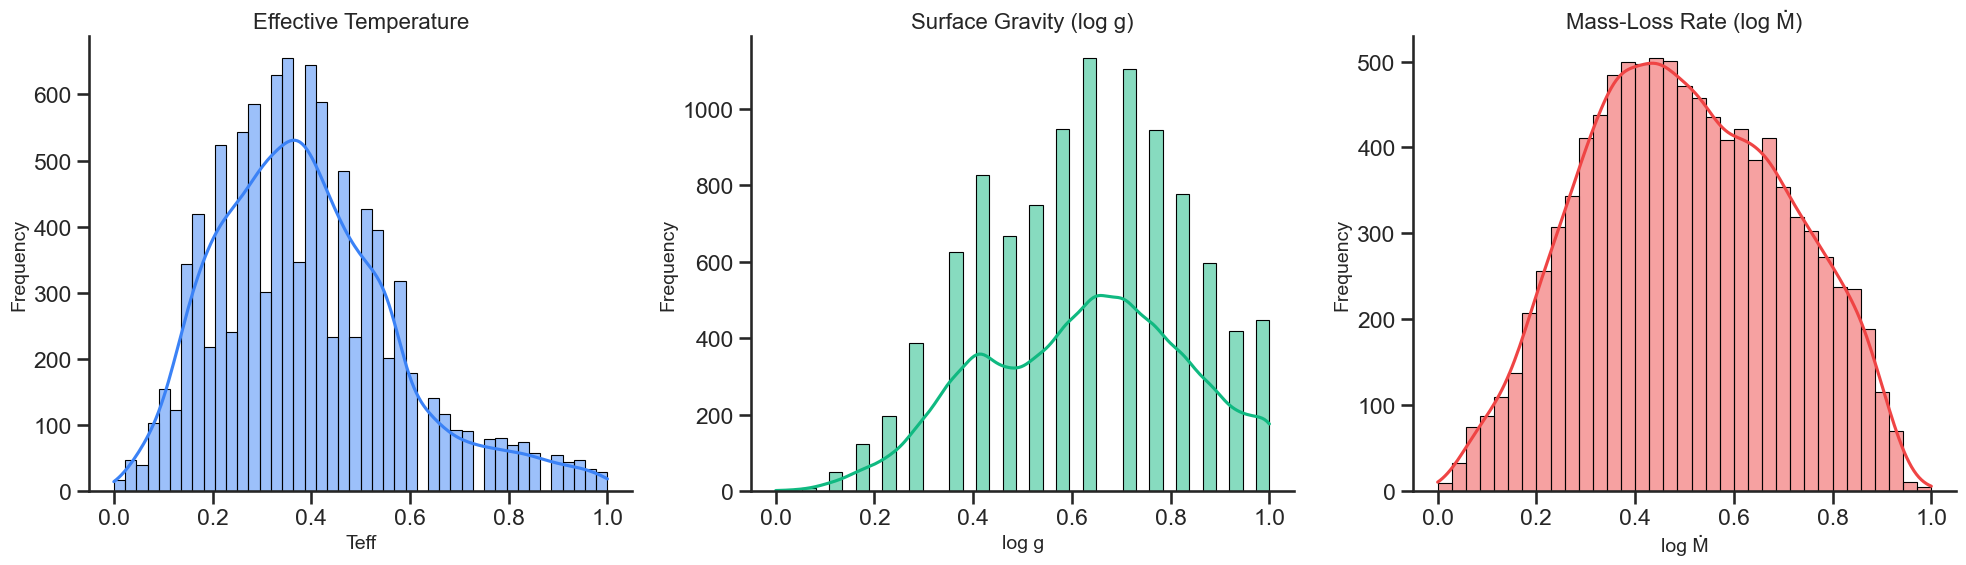

In [11]:
#Plot of y_scaled

#Create figure with 3 subplots
sns.set_theme(style="ticks", context="talk")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

#Colors for each plot
colors = ["#3b82f6", "#10b981", "#ef4444"]  

#Titles and labels
titles = ["Effective Temperature", "Surface Gravity (log g)", "Mass-Loss Rate (log Ṁ)"]
xlabels = ["Teff", "log g", "log Ṁ"]

#Draw each histrogam
for i in range(3):
    sns.histplot(
        y_scaled[:, i],
        kde=True,
        color=colors[i],
        edgecolor="black",
        linewidth=0.8,
        ax=axes[i]
    )

    #Visual configs
    axes[i].set_title(titles[i], fontsize=16)
    axes[i].set_xlabel(xlabels[i], fontsize=14)
    axes[i].set_ylabel("Frequency", fontsize=14)
    sns.despine(ax=axes[i])

#show figure
plt.tight_layout()
plt.show()


#### Training, validation and test separation
To properly evaluate a model its common to separate the data in three sets
* Training data: Data used by the model to learn a task
* Validation data: Data used during training to evaluate generalization or used for model optimization
* Testing data: Data which the model have never seen

In [12]:
X_train,X_test,y_train,y_test = train_test_split(X_reshaped,y_scaled,test_size=0.2, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 0.2, random_state=0)

#Lets see the resulting dimensions for each matrix
print("X_train shape: ", X_train.shape)
print("X_val shape: ", X_val.shape)
print("X_test shape: ", X_test.shape)

print("\ny_train shape: ", y_train.shape)
print("y_val shape: ", y_val.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (6400, 200, 1)
X_val shape:  (1600, 200, 1)
X_test shape:  (2000, 200, 1)

y_train shape:  (6400, 3)
y_val shape:  (1600, 3)
y_test shape:  (2000, 3)


## 3. Model Training
---
To predict `Teff`, `Logg` and `LogMdot` we will use a `Convolutional Neural Network` (CNN)

#### Model architecture 


In [13]:
def build_conv1D_model(input_shape= (200,1)):
    inputs = Input(shape=input_shape)

    #Grab inputs and add a Conv1D layer
    x = Conv1D(filters=32, kernel_size=7, activation='relu', name="Conv1D_1")(inputs)    
    #Grab x and add a MaxPooling layer 
    x = MaxPooling1D()(x)


    #Flatt -> features founded by CNN
    x = Flatten()(x)

    #Add a regression head
    #--------- Regression head -----------
    x = Dense(64, activation='relu')(x)
    
    #One neuron per each output
    outputs = Dense(3, activation='linear')(x)
    #------------------------------------

    #build the model connecting inputs and ouputs
    model = Model(inputs = inputs, outputs=outputs)

    return model
    



In [14]:
cnn_model = build_conv1D_model()

#We can see the details of the model we created using .summary()
cnn_model.summary()

2026-10-23 00:17:12.327503: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-10-23 00:17:12.327634: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-23 00:17:12.327642: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-10-23 00:17:12.327671: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-23 00:17:12.327680: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_1 (Conv1D)               │ (None, 194, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 97, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3104)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       198,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,171 (778.01 KB)

 Trainable params: 199,171 (778.01 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters can be used to estimate model complexity.  
*Note: model complexity does not depend solely on the number of parameters, but also on other factors such as the type of model or regularization techniques.*

In [15]:

#Lets compile out model (apply configurations for training)

mse_loss = 'mse' # Loss funciton which the model optimizes
adam_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4) # How do we update the parameters of the model
mse_metric = ['mse'] #metrics that we want to see during training

cnn_model.compile(loss=mse_loss, optimizer=adam_optimizer, metrics=mse_metric)

#Now we are ready to train our model!


#### Model training 

In [16]:
ep = 50 

#If vall loss dont improve in 5 epochs stop -> overfitting
callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=ep,
    callbacks=[callback],
    verbose=1
)

Epoch 1/50


2026-10-23 00:17:12.696802: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0520 - mse: 0.0520 - val_loss: 0.0317 - val_mse: 0.0317
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0305 - mse: 0.0305 - val_loss: 0.0283 - val_mse: 0.0283
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0269 - mse: 0.0269 - val_loss: 0.0251 - val_mse: 0.0251
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0243 - mse: 0.0243 - val_loss: 0.0237 - val_mse: 0.0237
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0210 - mse: 0.0210 - val_loss: 0.0198 - val_mse: 0.0198
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0175 - mse: 0.0175 - val_loss: 0.0156 - val_mse: 0.0156
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0151 - mse: 0.0151 - val_loss: 0.0141 - val_mse: 0.0141
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0134 - mse: 0.0134 - val_loss: 0.0127 - val_mse: 0.0127
Epoch 9/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0122 

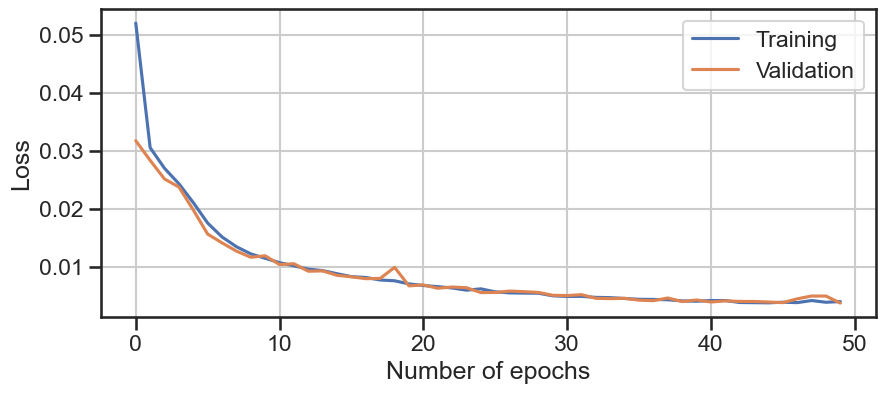

In [17]:
#We must plot the training history of the model to search for overfitting
train_loss = history.history['loss']
val_loss = history.history['val_loss']

#Create the figure
plt.figure(figsize=(10,4))

#Draw both plots
plt.plot(range(len(train_loss)), train_loss, label="Training")
plt.plot(range(len(val_loss)), val_loss, label="Validation")

#Visual configs
plt.xlabel("Number of epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()


In [18]:
#Save model 
cnn_model.save("cnn_model.keras")

## 4. Model Evaluation
---

Lets test our model with `X_test` dataset

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


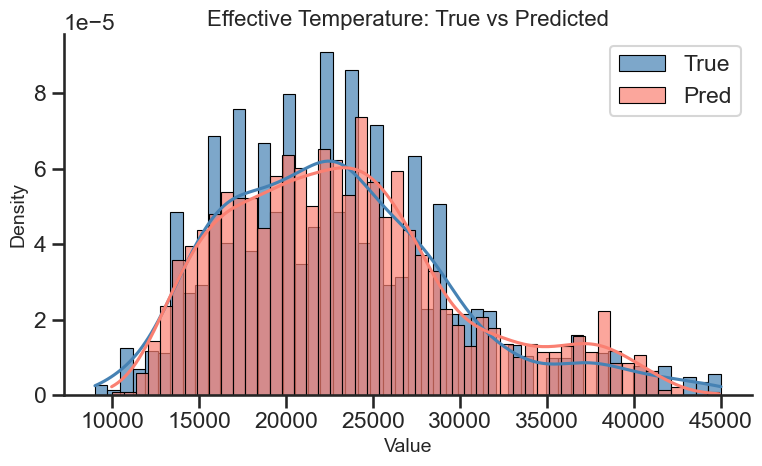

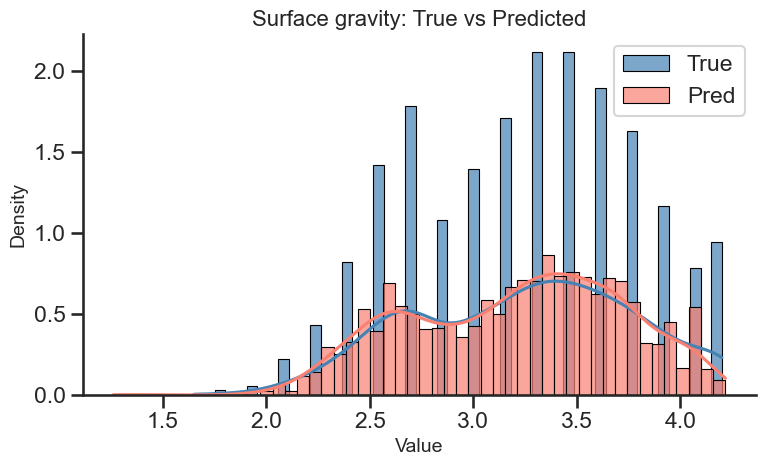

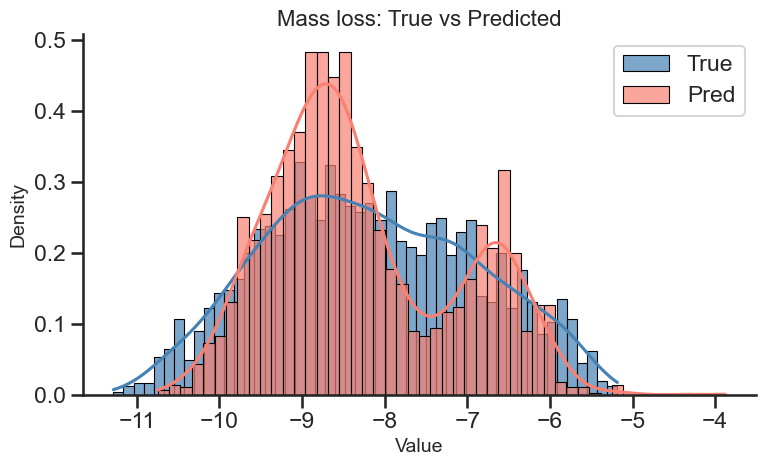

In [19]:
#Model's predictions
y_pred_scaled = cnn_model.predict(X_test)
y_pred = scaler.inverse_transform(y_pred_scaled) #Return to parameter's scale

#Real values
y_real = scaler.inverse_transform(y_test)

plot_true_pred_hist(true_values=y_real[:, 0], pred_values=y_pred[:, 0], title="Effective Temperature: True vs Predicted")
plot_true_pred_hist(true_values=y_real[:, 1], pred_values=y_pred[:, 1], title="Surface gravity: True vs Predicted")
plot_true_pred_hist(true_values=y_real[:, 2], pred_values=y_pred[:, 2], title="Mass loss: True vs Predicted")


T_eff – CNN
  MSE: 1776207.54
  MAE: 870.84
  R²:  0.961

Log g – CNN
  MSE: 0.02
  MAE: 0.11
  R²:  0.923

LOGMDOT – CNN
  MSE: 0.24
  MAE: 0.39
  R²:  0.852



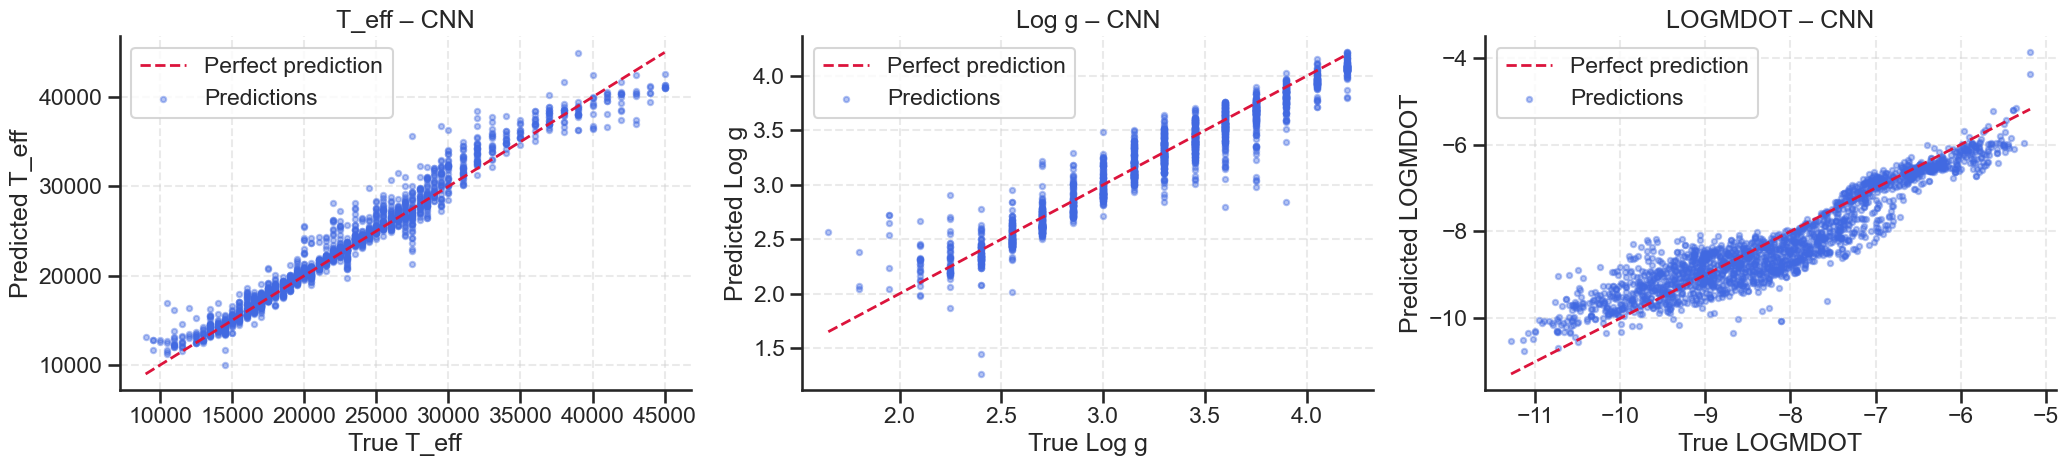

In [20]:
#Lets calculate metrics and see the results
plot_results(y_real, y_pred, model_name="CNN")

## Activity
---
The implemented model was quite simple. Try to improve the results

You may do the following modifications:
* Add `Conv1D`, `MaxPooling1D`, `Dense` or other layers
* Change activation functions: `'relu'`, `'sigmoid'`,  `'tanh'`, `'LeakyReLu'`, `'elu'`, `'gelu'`
* Increment the number of epochs
* Change learning rate or `optimizator`
* ...

In [21]:
def build_better_conv1D_model(input_shape= (200,1)):
    inputs = Input(shape=input_shape)

    ####################################
    #         Change this code
    ####################################
    
    #Grab inputs and add a Conv1D layer
    x = Conv1D(filters=32, kernel_size=7, activation='relu', name="Conv1D_1")(inputs)    
    #Grab x and add a MaxPooling layer 
    x = MaxPooling1D()(x)


    #Flatt -> features founded by CNN
    x = Flatten()(x)

    #Add a regression head
    #--------- Regression head -----------
    x = Dense(64, activation='relu')(x)

    #One neuron per each output
    outputs = Dense(3, activation='linear')(x)
    #------------------------------------
    
    ####################################

    #build the model connecting inputs and ouputs
    model = Model(inputs = inputs, outputs=outputs)

    return model

In [22]:
#Train your model

In [23]:
#Plot training history

In [24]:
#Evaluate your model

## 4. Uncertainty estimation
---


Traditional Neural Networks output a single, deterministic value for a given input. However, a model can experience uncertainty, meaning its not completly sure of the given awnser.


To capture this in machine learning. We use `Bayesian Neural Networks`which replaces traditional fixed weights with probability ditribution, allowing the model to express uncertainity abouts its own parameters. Furthermore the output will also be a probability distribution:

$$y \sim N(\mu_x, \sigma_y^2)$$
<br><br>
 
![Diagram: traditional neural network vs Bayesian neural network](Figures/Traditional_and_bayesian.png)

Since the output is now a probability distribution, a natural measure of the model's uncertainty is its standard deviation ($\sigma$).



### Types of uncertainty 

Uncertainty measures how confident a model is about a prediction. In machine learning, we categorize it into two types:

* **Aleatoric Uncertainty**.   

    This is the uncertainty caused by randomness, noise, or the environment inherent to the data. It cannot be reduced by collecting more data due to its stochastic nature.  In stellar analysis, this includes:  
    - Observational noise.
    - Synthetic data generation.
    - ...

* **Epistemic Uncertainty**.   

    This is the uncertainty caused by the model's lack of knowledge. Unlike aleatoric uncertainty, it can be reduced by providing more training data or improving the model.

---
### Monte Carlo Dropout
Dropout is a regularization technique that randomly 'deactivates' neurons with a probability $p$. The state of a neuron can be modeled using a Bernoulli distribution:

$$P(X = x) = \begin{cases} p & \text{if } x = 1 \\ 1 - p & \text{if } x = 0 \end{cases}$$

Interestingly, this behaves as a mathematical approximation of a `Bayesian Neural Network`

To estimate uncertainty, **Monte Carlo (MC) Dropout** leaves dropout enabled at test time and runs multiple forward passes for the same input using different dropout masks, allowing to estimate the `epistemic uncertainty` associated with the model's weights.
 

The result is a distribution of predictions rather than a single point estimate:
* **Mean**: Best prediction
* **Standar deviation**: epistemic uncertainity



### Monte Carlo Dropout in CNNs


![Diagram: standard 1D CNN](Figures/1d_cnn.png)
![Diagram: Bayesian 1D CNN with Monte Carlo Dropout](Figures/bayesian_1d_cnn.png)

A `Bayesian 1D CNN` deactivets a filter to estimate uncertaity  

#### Data preprocessign

Implementation of a Convolutional Nerual Network with Monte Carlo Dropout to predict uncertainity in efective temperature predictions

In [25]:
#Normalization
teff = y_new[:, 0:1]
teff_scaler = MinMaxScaler()
teff_scaler.fit(teff)
teff_scaled = teff_scaler.transform(teff)

In [26]:
#Training, validation and testing
X_bayesian_train, X_bayesian_test, teff_train, teff_test = train_test_split(X_reshaped, teff_scaled, test_size=0.2, random_state=0)
X_bayesian_train, X_bayesian_val, teff_train, teff_val = train_test_split(X_bayesian_train, teff_train, test_size=0.2, random_state=0)

#### Model architecture

In [27]:
#Modified Layers that keeps drop out always active
@tf.keras.utils.register_keras_serializable()
class MCDropout(layers.Dropout):
    def call(self, inputs, training=None):
        return super().call(inputs, training=True)

@tf.keras.utils.register_keras_serializable()
class MCSpatialDropout1D(layers.SpatialDropout1D):
    def call(self, inputs, training=None):
        return super().call(inputs, training=True)


#Model's architecture
def build_bayesian_conv1D_model(input_shape=(200, 1), dropout_rate_cnn=0.1, drop_out_rate=0.1):
    inputs = Input(shape=input_shape)

    x = Conv1D(filters=32, kernel_size=7, activation='relu')(inputs)
    x = MaxPooling1D()(x)
    x = MCSpatialDropout1D(dropout_rate_cnn)(x)#drop filters

    x = Flatten()(x)
    x = MCDropout(drop_out_rate)(x) #Drop neurons
    x = Dense(64, activation='relu')(x)

    outputs = Dense(1, activation='linear')(x)  
    return Model(inputs=inputs, outputs=outputs, name="Bayesian_1D_CNN")


In [28]:
architecture_example = build_bayesian_conv1D_model(dropout_rate_cnn=0.1, drop_out_rate=0.3)
architecture_example.summary()

Model: "Bayesian_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 200, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 194, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 97, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mc_spatial_dropout1d            │ (None, 97, 32)         │             0 │
│ (MCSpatialDropout1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3104)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mc_dropout (MCDropout)          │ (None, 3104)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       198,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,041 (777.50 KB)

 Trainable params: 199,041 (777.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0896 - mse: 0.0896 - val_loss: 0.0800 - val_mse: 0.0800
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0695 - mse: 0.0695 - val_loss: 0.0599 - val_mse: 0.0599
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0517 - mse: 0.0517 - val_loss: 0.0551 - val_mse: 0.0551
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0460 - mse: 0.0460 - val_loss: 0.0505 - val_mse: 0.0505
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0425 - mse: 0.0425 - val_loss: 0.0382 - val_mse: 0.0382
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0358 - mse: 0.0358 - val_loss: 0.0357 - val_mse: 0.0357
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0304 - mse: 0.0304 - val_loss: 0.0345 - val_mse: 0.0345
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0271 - mse: 0.0271 - val_loss: 0.0238 - val_mse: 0.0238
Epoch 9/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/

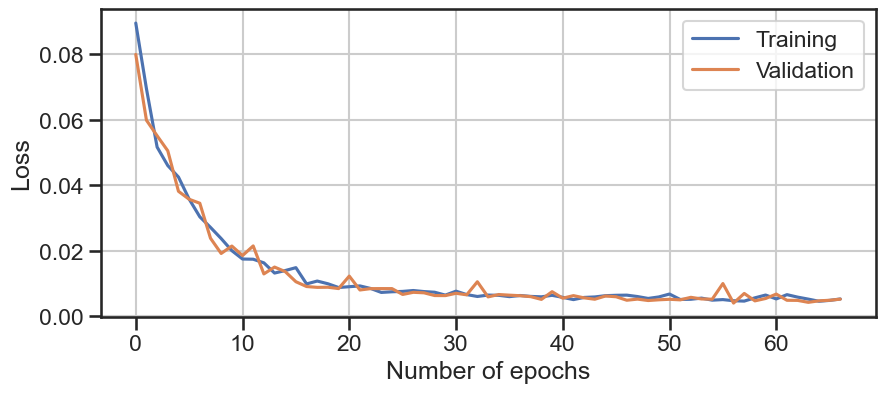

In [ ]:
#Load model to avoid training times
load_model = True #Change this to True if you want to load an already train model


if load_model:
    if IN_COLAB:
        !gdown https://drive.google.com/uc?id=1vudxrWGHtQH7Y0BNM3LlV2OQSfAlm-le
    bayesian_cnn_path = "bayesian_cnn (1).keras"
    if os.path.exists(bayesian_cnn_path):
        bayesian_cnn_model = keras.models.load_model(bayesian_cnn_path)

else:
    
    #Comiple and train the bayesian model
    bayesian_cnn_model = build_bayesian_conv1D_model(dropout_rate_cnn=0.1, drop_out_rate=0.3)
    bayesian_cnn_model.compile(loss='mse', optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), metrics=['mse'])

    callback = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    history_bayes = bayesian_cnn_model.fit(
        x= X_bayesian_train, 
        y= teff_train,
        validation_data=(X_bayesian_val, teff_val),
        epochs=100,
        callbacks=[callback],
        verbose=1
    )

    #We must plot the training history of the model to search for overfitting
    train_loss = history_bayes.history['loss']
    val_loss = history_bayes.history['val_loss']

    #Create the figure
    plt.figure(figsize=(10,4))

    #Draw both plots
    plt.plot(range(len(train_loss)), train_loss, label="Training")
    plt.plot(range(len(val_loss)), val_loss, label="Validation")

    #Visual configs
    plt.xlabel("Number of epochs")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.legend()
    plt.show()


In [30]:
#Save the trained model
save_model = False #Change if you want to save your model
if save_model:
    bayesian_cnn_model.save("bayesian_cnn.keras")

### Monte Carlo Sampling (Inference)
---

#### Custom functions

In [31]:
def make_bayesian_prediction(T, data, bayesian_model,scaler):
    #Make T predictions on the data using the bayesian model
    preds = []
    for i in range(T):
        pred_scaled = bayesian_model.predict(data, verbose=0)
        pred = scaler.inverse_transform(pred_scaled)
        preds.append(pred)

    return np.array(preds)


def plot_bayesian_results(y_true, y_pred, y_std, model_name, n_show=50, seed=42):
    #Predicted vs true for a random subset of spectra with a 95% confidence interval (±2σ)


    #Metrics (using all the spectra)
    print(f"Teff – {model_name}")
    print(f"  MSE: {mean_squared_error(y_true, y_pred):.2f}")
    print(f"  MAE: {mean_absolute_error(y_true, y_pred):.2f}")
    print(f"  R²:  {r2_score(y_true, y_pred):.3f}\n")

    #Pick random subset of spectra for visual clarity
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y_true), size=n_show, replace=False)

    #Plot 
    plt.figure(figsize=(10, 6))

    #Perfect prediction
    lims = [y_true.min(), y_true.max()]
    plt.plot(lims, lims, color="crimson", linestyle="--", linewidth=2, label="Perfect prediction")

    #Points with Error bars (±2σ)
    plt.errorbar(
        y_true[idx], y_pred[idx], color="royalblue", markersize=5, fmt='o', #Points configuration
        yerr = 2*y_std[idx], ecolor="lightsteelblue", capsize=3,             #Error bar configuration
        label="Mean prediction ± 2σ"
    )

    plt.xlabel("True Teff [K]")
    plt.ylabel("Predicted Teff [K]")
    plt.title(f"True vs predicted Teff ({n_show} random spectra)")
    plt.legend(loc="lower right")
    plt.grid(True, linestyle="--", alpha=0.4)
    sns.despine()   # remove top and right borders
    plt.tight_layout()
    plt.show()



def plot_best_worst_spectra(preds, y_true, n_bins=30):
    '''
    Histogram of the T forward passes for the spectrum with the largest
    and the smallest error.
    '''

    #Obtain values for each spectrum
    y_true = y_true[:, 0]                    #Transform shape (N, 1) -> (N,)
    y_mean = preds[:, :, 0].mean(axis=0)     #mean of the T predictions
    y_std = preds[:, :, 0].std(axis=0)       #std of the T predictions
    error = np.abs(y_mean - y_true)          #error of the mean prediction

    #Find index of the best and worst prediction
    idx_worst = np.argmax(error)
    idx_best = np.argmin(error)

    indices = [idx_best, idx_worst]
    names = ["Smallest error", "Largest error"]
    colors = ["seagreen", "tomato"]

    #Same bins for both histograms to better comparison
    selected = preds[:, indices, 0]
    bins = np.linspace(selected.min(), selected.max(), n_bins + 1)

    #Draw plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

    for i in range(2):
        idx = indices[i]
        ax = axes[i]

        #Draw all forward passes
        ax.hist(preds[:, idx, 0], bins=bins, color=colors[i], edgecolor="white")
        #Draw mean prediction
        ax.axvline(y_mean[idx], color="navy", linewidth=2.5, label="Mean prediction")

        ax.set_title(
            f"{names[i]} (spectrum #{idx})\n"
            f"Mean = {y_mean[idx]:.0f} K   Std = {y_std[idx]:.0f} K   MAE = {error[idx]:.0f} K",
            fontsize=13
        )

        ax.set_xlabel("Predicted Teff [K]")
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.legend()

    axes[0].set_ylabel("Number of forward passes")
    fig.suptitle("Forward-pass predictions", fontsize=16)
    sns.despine()
    plt.tight_layout()
    plt.show()


### Model Evaluation

In [32]:
#Make T predictions for each spectrum
T = 50
teff_preds = make_bayesian_prediction(T, X_bayesian_test, bayesian_cnn_model, teff_scaler)   
teff_pred = teff_preds.mean(axis=0)   # Best prediction
teff_std  = teff_preds.std(axis=0)    # uncertainity
teff_true = teff_scaler.inverse_transform(teff_test)


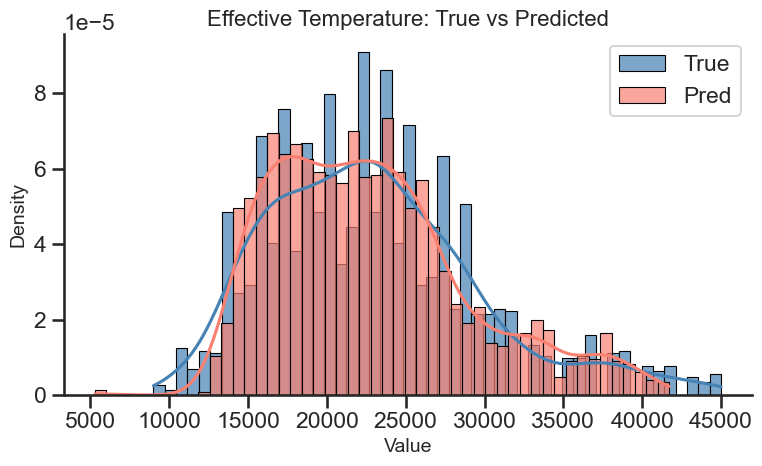

In [33]:
#Predictions of the model (mean over the T predictions) vs true predictions
plot_true_pred_hist(true_values=teff_true[:, 0], pred_values=teff_pred[:, 0], title="Effective Temperature: True vs Predicted")


T_eff – Bayesian CNN
  MSE: 2453385.50
  MAE: 1011.88
  R²:  0.946



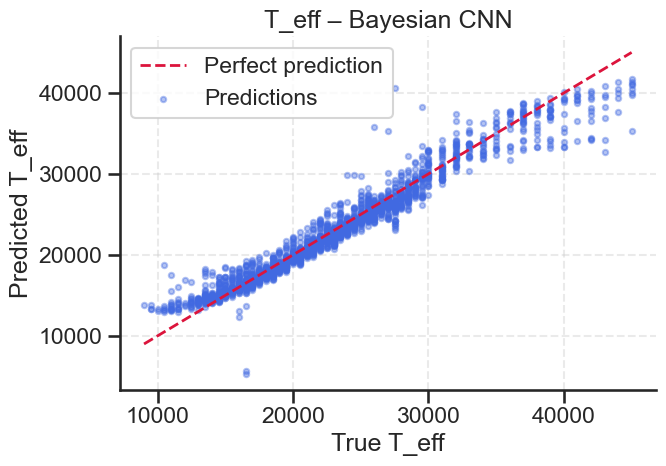

In [34]:
#Predictions of the model (mean over the T predictions) vs true predictions
plot_results(teff_true, teff_pred, "Bayesian CNN", targets=["T_eff"])

### Model Uncertainty

The advantage of ``Bayesian models`` is that we can leverage uncertainty to identify when predictions are unrelaiable.

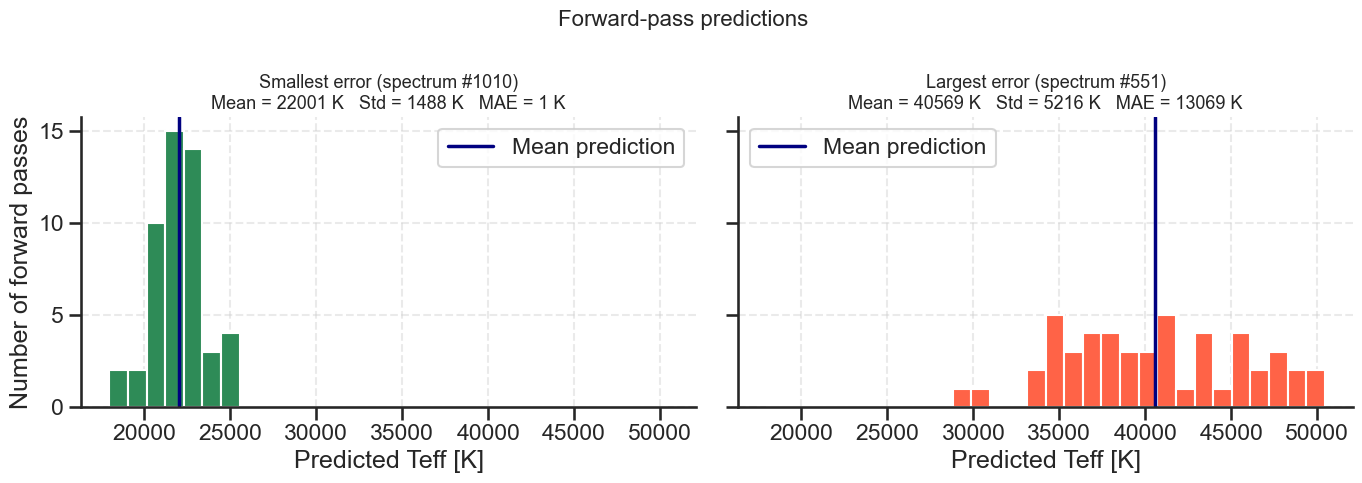

In [35]:
#Plot distirbution of the T predictions for the best and worst Teff prediction
plot_best_worst_spectra(teff_preds, teff_true)

Teff – BAYESIAN (MC Dropout)
  MSE: 2453385.50
  MAE: 1011.88
  R²:  0.946



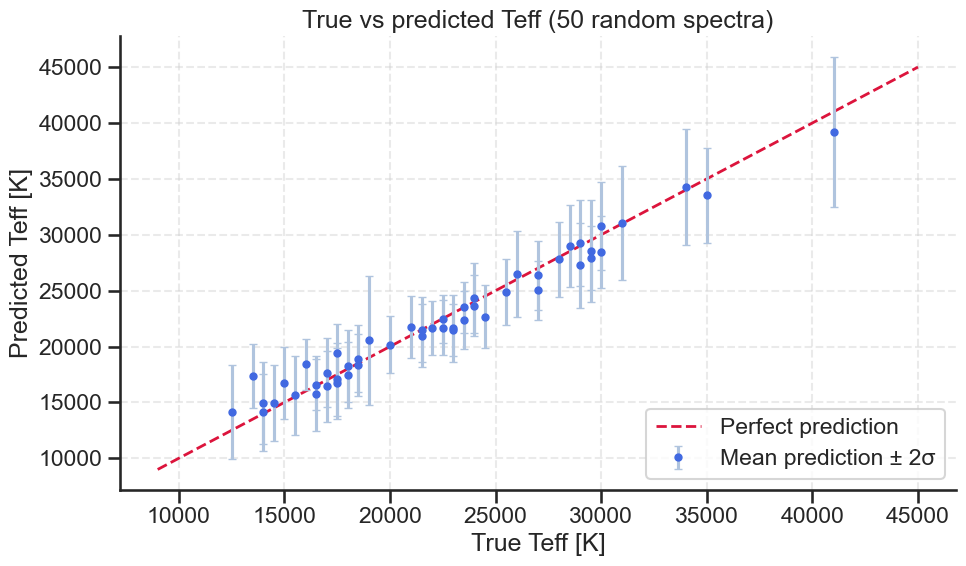

In [36]:
#We can plot a confidence interval by using the standard deviaton of the predictions
plot_bayesian_results(teff_true[:,0], teff_pred[:,0], teff_std[:,0],"BAYESIAN (MC Dropout)")

Now each prediction can be accompanied by an uncertainty, giving a range of likely values instead of a single number!